# K-Means Clustering

 - Unsupervised Machine Learning
 - is me bs bs "X" py kaam krna h "y" py ni 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler


In [2]:
df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# importing data in features
X = df[['age', 'fare']]

# NaN values ko mean se fill karna
X = X.fillna(X.mean()) 

# scale data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# perform cluster
kmeans = KMeans(n_clusters=3, random_state=42) # random_state add karne se result hamesha same aayega
kmeans.fit(X_scaled)

# assign clusters labels to the data
labels = kmeans.labels_
df['clusters'] = labels


In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


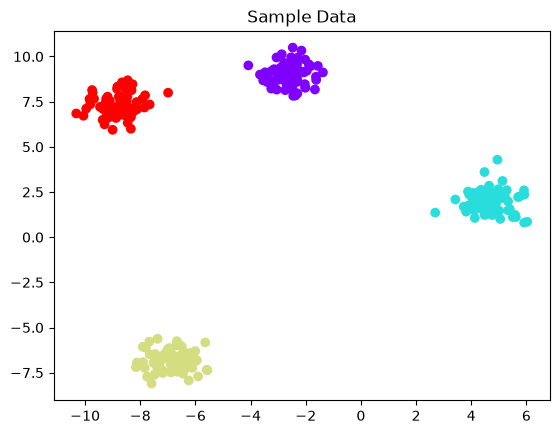

In [4]:
X, y = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=42)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap='rainbow')
plt.title('Sample Data')
plt.show()

## 2. Elbow Method - Sahi K Find Karna

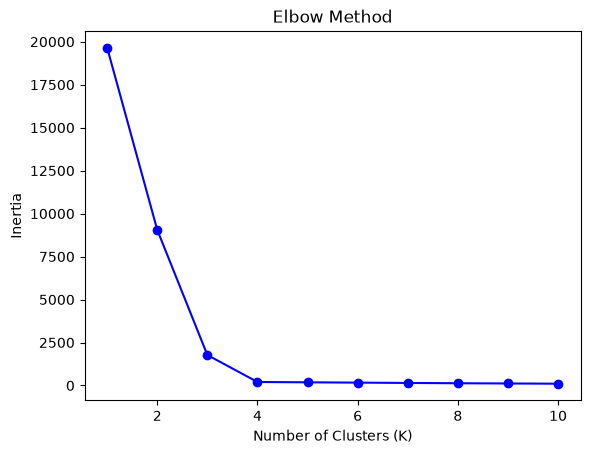

In [5]:
inertia = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X)
    inertia.append(km.inertia_)

plt.plot(K_range, inertia, 'bo-')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

## 3. K-Means Model Train Karna

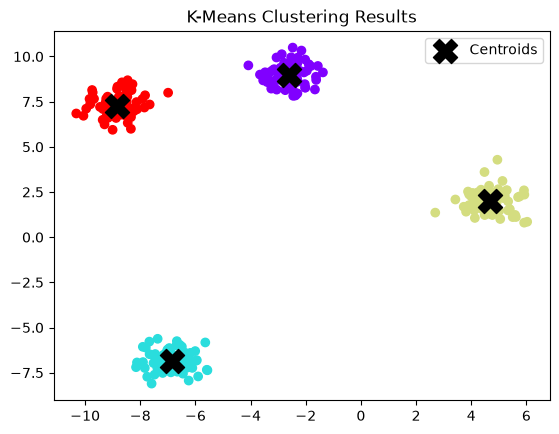

In [6]:
kmeans = KMeans(n_clusters=4, random_state=42)
y_kmeans = kmeans.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, cmap='rainbow')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], 
            s=300, c='black', marker='X', label='Centroids')
plt.title('K-Means Clustering Results')
plt.legend()
plt.show()

## 4. Prediction - Naya Data Point

In [7]:
new_points = np.array([[0, 0], [5, 5], [-2, 4]])
predictions = kmeans.predict(new_points)
print('Predictions:', predictions)

Predictions: [2 2 0]


# saving the model

In [9]:
# saving the model 
import joblib
joblib.dump(y_kmeans, 'KMeansClustering.joblib')

['KMeansClustering.joblib']

# load the save model

In [10]:
# load the save model
model_loaded  = joblib.load('KMeansClustering.joblib')